# Predicting a Country's Trust in AI

**Target:** `trust_ai_pct` (% of people in a country who trust AI). It is a continuous number, so this is a **regression** problem.

**Plan (5 steps)**
1. **Choose the inputs** — 4 predictors from the feature-selection step (no overlapping or "leaky" variables).
2. **Choose the models** — a do-nothing baseline, Linear Regression, a Decision Tree (CART) and a Random Forest.
3. **Test them fairly** — repeated 5-fold cross-validation, because 47 countries is too few for one train/test split.
4. **Compare** on MAE, RMSE and R², and pick the winner.
5. **Explain** the winner — what each input contributes and which countries it gets wrong.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, GridSearchCV, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#b4b2ac", "#52514e"

DATA_PATH = "archive/ai_trust_by_country.csv"   # public Kaggle survey data (not included in the repo)
df = pd.read_csv(DATA_PATH)
df["log_gdp"] = np.log(df["gdp_per_capita_usd"])   # GDP is very skewed, so use the log
print(df.shape)

(47, 44)


## Step 1 — Choose the inputs

We use the **4 predictors chosen in the feature-selection step**. Each one stands for a whole group of overlapping survey questions:

| Predictor | Stands for the group… |
|---|---|
| `safeguards_sufficient_pct` | AI readiness & governance (literacy, training, awareness of rules…) |
| `increased_efficiency_pct` | Workplace payoff from AI (revenue, employer training, AI strategy…) |
| `couldnt_work_without_ai_pct` | Dependence on AI at work |
| `log_gdp` | How rich the country is — kept as a background **control** |

**Deliberately left out**
- `accept_ai_pct`, `risks_outweigh_benefits_pct`, `sentiment` — these are **leakage**: they are basically another way of measuring trust itself, so using them would be like predicting this month's revenue from this month's sales.
- `expect_benefits_pct`, `experienced_benefits_pct`, `literacy_skills_pct`, `ai_training_pct` — they overlap heavily with the 4 above, so they add little new information (tested again in Step 6).

In [2]:
FEATURES = ["safeguards_sufficient_pct", "couldnt_work_without_ai_pct",
            "increased_efficiency_pct", "log_gdp"]
TARGET = "trust_ai_pct"

X = df[FEATURES]
y = df[TARGET]
X.describe().round(1)

,safeguards_sufficient_pct,couldnt_work_without_ai_pct,increased_efficiency_pct,log_gdp
count,47.0,47.0,47.0,47.0
mean,43.0,40.4,54.6,10.3
std,13.1,9.0,13.2,1.0
min,23.0,25.0,33.0,7.1
25%,34.0,35.0,44.5,10.0
50%,41.0,39.0,53.0,10.5
75%,50.5,45.5,62.0,11.0
max,73.0,67.0,88.0,11.8


## Step 2 — Choose the models

| Model | How it works, in one line | Why include it |
|---|---|---|
| **Baseline** | Always predicts the average trust (≈46%) | The bar to beat — any real model must do better than this |
| **Linear Regression** | Fits a straight-line formula: trust = a + b₁·safeguards + b₂·… | Simple, explainable, works well when relationships are roughly straight lines |
| **Decision Tree (CART)** | Asks yes/no questions ("safeguards > 50%?") and predicts the average of each final group | Easy to draw; catches thresholds. *Note: sklearn's `DecisionTreeRegressor` **is** the CART algorithm, so "Decision Tree" and "CART" are the same model.* |
| **Random Forest** | Builds hundreds of slightly different trees and averages them | Usually more accurate and stable than one tree |

**Tuning:** the tree and the forest have settings (how deep the tree may grow, how many countries each final group needs). With only 47 countries a deep tree would just memorise them, so the depth is kept small and the best setting is picked **inside** each training fold (`GridSearchCV`), so the test countries never influence the choice.

In [3]:
def build_models():
    inner_cv = KFold(5, shuffle=True, random_state=0)
    return {
        "Baseline (mean)": DummyRegressor(strategy="mean"),
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Decision Tree (CART)": GridSearchCV(
            DecisionTreeRegressor(random_state=0),
            {"max_depth": [2, 3, 4], "min_samples_leaf": [3, 5, 8]},
            cv=inner_cv, scoring="neg_mean_absolute_error"),
        "Random Forest": GridSearchCV(
            RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1),
            {"max_depth": [3, None], "min_samples_leaf": [2, 4]},
            cv=inner_cv, scoring="neg_mean_absolute_error"),
    }

## Step 3 — Why cross-validation, not one train/test split

With 47 countries, a 70/30 split leaves only **~14 test countries**. Which 14 you happen to pick changes the score a lot.
Below: the *same* Linear Regression, scored on 50 different random 70/30 splits.

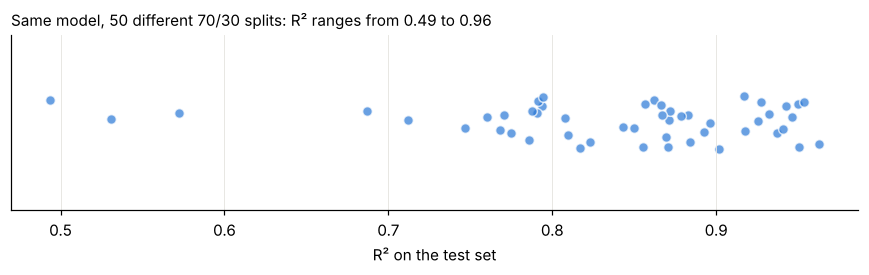

In [4]:
split_r2 = []
for seed in range(50):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=seed)
    m = LinearRegression().fit(X_tr, y_tr)
    split_r2.append(r2_score(y_te, m.predict(X_te)))
split_r2 = np.array(split_r2)

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.scatter(split_r2, np.random.default_rng(0).uniform(-0.3, 0.3, len(split_r2)),
           s=40, color=BLUE, alpha=0.7, edgecolor="white", linewidth=1)
ax.set_yticks([]); ax.set_ylim(-1, 1); ax.grid(axis="y", visible=False)
ax.set_xlabel("R² on the test set")
ax.set_title(f"Same model, 50 different 70/30 splits: R² ranges from {split_r2.min():.2f} to {split_r2.max():.2f}",
             loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Takeaway:** one lucky split could report R² ≈ 0.96 and an unlucky one ≈ 0.5 — for the *same* model. That is why we use **repeated 5-fold cross-validation**:

1. Split the 47 countries into 5 groups (~9–10 each).
2. Train on 4 groups, predict the 5th. Rotate until **every country has been predicted once by a model that never saw it**.
3. Score those 47 "unseen" predictions.
4. Repeat the whole thing 5 times with different random groupings and average, so no single grouping decides the result.

In [5]:
N_REPEATS = 5

def evaluate(models, X, y, n_repeats=N_REPEATS):
    rows, oof = [], {}
    for name, model in models.items():
        scores, preds = [], []
        for r in range(n_repeats):
            cv = KFold(5, shuffle=True, random_state=r)
            p = cross_val_predict(model, X, y, cv=cv)      # each country predicted by a model that never saw it
            preds.append(p)
            scores.append([mean_absolute_error(y, p), mean_squared_error(y, p) ** 0.5, r2_score(y, p)])
        s = np.array(scores)
        rows.append({"Model": name,
                     "MAE": s[:, 0].mean(), "MAE ±": s[:, 0].std(),
                     "RMSE": s[:, 1].mean(), "RMSE ±": s[:, 1].std(),
                     "R²": s[:, 2].mean(), "R² ±": s[:, 2].std()})
        oof[name] = np.mean(preds, axis=0)                # average unseen prediction per country
    return pd.DataFrame(rows).set_index("Model").round(2), oof

results, oof_preds = evaluate(build_models(), X, y)
results

,MAE,MAE ±,RMSE,RMSE ±,R²,R² ±
Model,,,,,,
Baseline (mean),9.89,0.13,12.60,0.14,-0.04,0.02
Linear Regression,3.58,0.17,4.59,0.19,0.86,0.01
Decision Tree (CART),5.95,0.22,7.15,0.30,0.66,0.03
Random Forest,4.32,0.14,5.36,0.17,0.81,0.01


## Step 4 — Compare the models

How to read the metrics:
- **MAE** — on average, how many percentage points the prediction is off. *Lower is better.*
- **RMSE** — like MAE, but big misses count extra. If RMSE is much bigger than MAE, the model has a few large misses. *Lower is better.*
- **R²** — the share of the differences in trust between countries that the model explains (1 = all, 0 = no better than guessing the average). *Higher is better.*
- **±** — how much the score moved across the 5 repeats (small = stable).

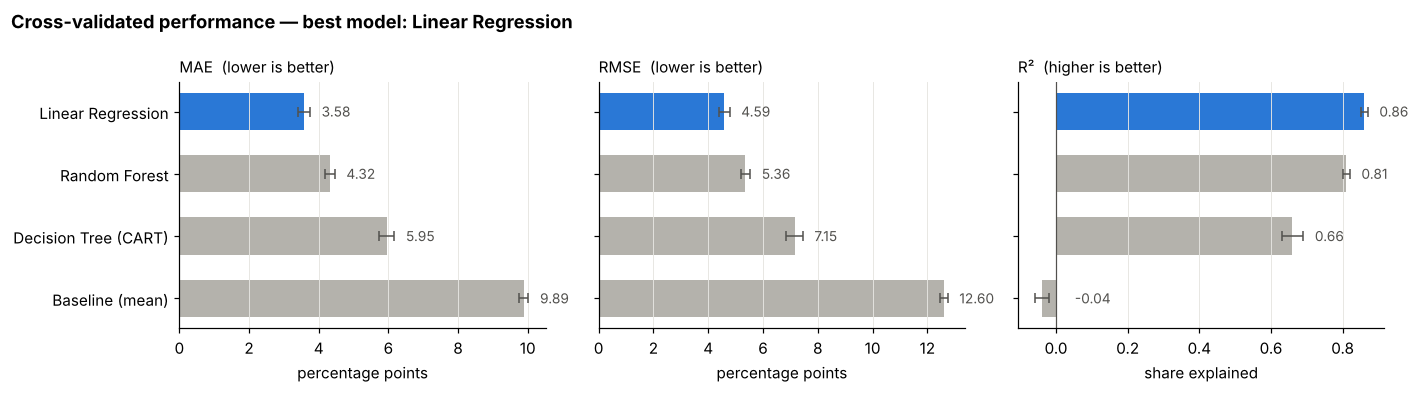

In [6]:
best = results.drop("Baseline (mean)")["MAE"].idxmin()
order = results.sort_values("MAE", ascending=False).index
colors = [BLUE if m == best else GREY for m in order]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, metric, better in zip(axes, ["MAE", "RMSE", "R²"], ["lower", "lower", "higher"]):
    vals = results.loc[order, metric]
    ax.barh(order, vals, xerr=results.loc[order, metric + " ±"], color=colors,
            height=0.6, error_kw={"ecolor": INK, "lw": 1, "capsize": 3})
    errs = results.loc[order, metric + " ±"]
    for i, (v, e) in enumerate(zip(vals, errs)):
        ax.text(max(v, 0) + e, i, f"   {v:.2f}", va="center", fontsize=9, color=INK)
    ax.set_title(f"{metric}  ({better} is better)", loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
    if metric == "R²":
        ax.axvline(0, color=INK, lw=0.8)
axes[0].set_xlabel("percentage points"); axes[1].set_xlabel("percentage points"); axes[2].set_xlabel("share explained")
fig.suptitle(f"Cross-validated performance — best model: {best}", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### Findings

- **Every model beats the baseline.** Guessing the average is off by about 10 percentage points; the models cut that to 3.6–6. So the 4 inputs genuinely carry information about trust.
- **Linear Regression wins on all three metrics** — on average its prediction is **about 3.6 percentage points off**, and it explains **about 86%** of the differences in trust between countries.
- **Random Forest is a close second** (≈4.3 pp off, ≈81%). **The single Decision Tree is weakest** (≈6 pp off, ≈66%): with 47 countries each final group of the tree holds only a handful of countries, so its predictions are coarse "step" averages.
- **Why does the simplest model win?** Exploratory scatter plots showed roughly straight-line relationships between these inputs and trust. With only ~38 countries to train on in each fold, the flexible models have too little data to learn anything beyond a straight line — their extra flexibility mostly fits noise.
- **The ranking is stable** — the ± values are small, so it isn't a fluke of one particular split.

*Note on R²:* these R² values score all 47 unseen predictions together. Averaging R² over each fold of ~9 countries instead gives lower, noisier numbers (≈0.78). Both are valid, as long as one method is quoted consistently.

## Step 5 — Explain the winning model

### 5a. Predicted vs actual (unseen predictions)
Each dot is a country, predicted by a model that **never saw that country**. Dots on the dashed line are perfect predictions.

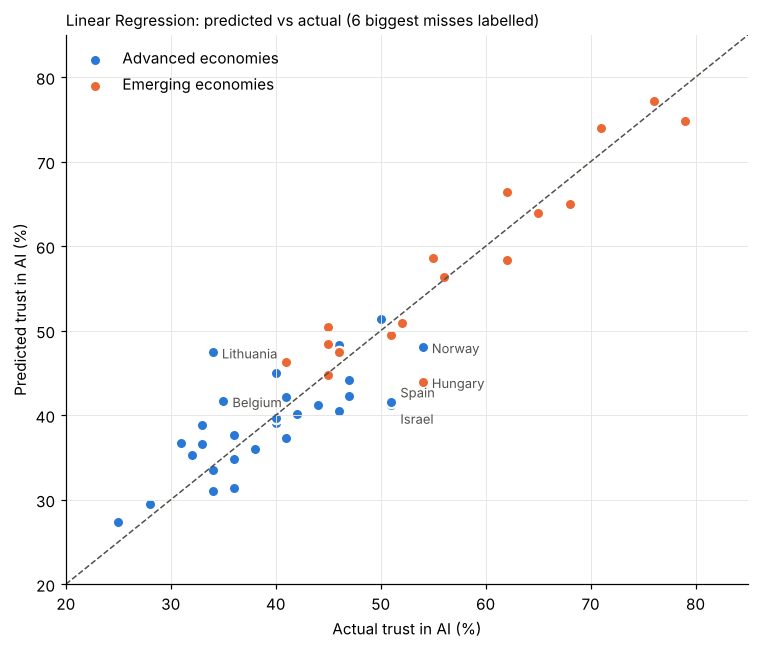

Trust LOWER than the model expects:


,country,actual,predicted,error (actual − predicted)
26,Lithuania,34,47.4,-13.4
3,Belgium,35,41.7,-6.7
15,France,33,38.8,-5.8
10,Czech Republic,31,36.8,-5.8


Trust HIGHER than the model expects:


,country,actual,predicted,error (actual − predicted)
31,Norway,54,48.1,5.9
40,Spain,51,41.6,9.4
21,Israel,51,41.2,9.8
18,Hungary,54,43.9,10.1


In [7]:
pred = oof_preds[best]
resid = y - pred
fig, ax = plt.subplots(figsize=(7, 6))
for etype, col in [("advanced", BLUE), ("emerging", ORANGE)]:
    m = df["economy_type"] == etype
    ax.scatter(y[m], pred[m], s=55, color=col, edgecolor="white", linewidth=1.5,
               label=f"{etype.capitalize()} economies")
lims = [20, 85]
ax.plot(lims, lims, "--", color=INK, lw=1)
ax.set_xlim(lims); ax.set_ylim(lims)
nudge = {"Israel": (6, -12), "Spain": (6, 3)}
for i in resid.abs().sort_values(ascending=False).index[:6]:
    ax.annotate(df.loc[i, "country"], (y[i], pred[i]), xytext=nudge.get(df.loc[i, "country"], (6, -4)),
                textcoords="offset points", fontsize=8.5, color=INK)
ax.set_xlabel("Actual trust in AI (%)"); ax.set_ylabel("Predicted trust in AI (%)")
ax.set_title(f"{best}: predicted vs actual (6 biggest misses labelled)", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

miss = pd.DataFrame({"country": df["country"], "actual": y, "predicted": pred.round(1),
                     "error (actual − predicted)": resid.round(1)})
print("Trust LOWER than the model expects:")
display(miss.sort_values("error (actual − predicted)").head(4))
print("Trust HIGHER than the model expects:")
display(miss.sort_values("error (actual − predicted)").tail(4))

**Findings**
- About **3 in 4 countries are predicted within ±5 percentage points**, and errors are balanced between advanced and emerging economies (average error ≈ 0 for both), so the model isn't systematically biased towards one group.
- The high-trust emerging economies (top right: Nigeria, India, Egypt…) are predicted well.
- **Biggest misses:** **Lithuania** trusts AI much *less* than its scores suggest (actual 34% vs predicted ≈47%). **Hungary, Israel and Spain** trust it *more* than predicted (by ≈10 pp). These likely reflect factors the survey inputs don't capture, such as local politics, media coverage or recent AI events.

### 5b. What each input contributes

Linear Regression gives one number per input: **how many percentage points trust changes when that input rises, holding the others fixed.**
To make the numbers comparable we show the effect of **+10 percentage points** for the survey inputs, and of **doubling GDP per person** for GDP.
The error bars come from refitting on 1,000 bootstrap resamples of the countries — if a bar crosses zero, we can't be confident about the direction.

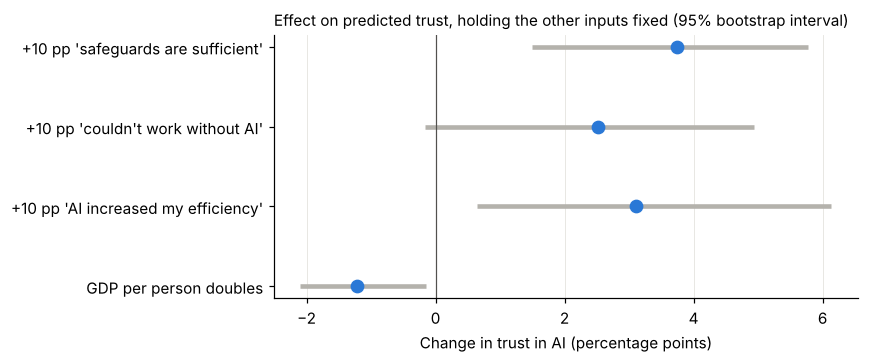

,effect,low,high
safeguards_sufficient_pct,3.75,1.50,5.77
couldnt_work_without_ai_pct,2.52,-0.16,4.94
increased_efficiency_pct,3.10,0.65,6.14
log_gdp,-1.21,-2.09,-0.15


In [8]:
lin = LinearRegression().fit(X, y)
scale = pd.Series({"safeguards_sufficient_pct": 10, "couldnt_work_without_ai_pct": 10,
                   "increased_efficiency_pct": 10, "log_gdp": np.log(2)})
labels = {"safeguards_sufficient_pct": "+10 pp 'safeguards are sufficient'",
          "couldnt_work_without_ai_pct": "+10 pp 'couldn't work without AI'",
          "increased_efficiency_pct": "+10 pp 'AI increased my efficiency'",
          "log_gdp": "GDP per person doubles"}

rng = np.random.default_rng(0)
boot = np.array([LinearRegression().fit(X.iloc[idx], y.iloc[idx]).coef_
                 for idx in (rng.integers(0, len(X), len(X)) for _ in range(1000))])
effect = pd.DataFrame({"effect": lin.coef_ * scale.values,
                       "low": np.percentile(boot, 2.5, axis=0) * scale.values,
                       "high": np.percentile(boot, 97.5, axis=0) * scale.values},
                      index=FEATURES)

fig, ax = plt.subplots(figsize=(8, 3.4))
ypos = np.arange(len(effect))[::-1]
ax.errorbar(effect["effect"], ypos,
            xerr=[effect["effect"] - effect["low"], effect["high"] - effect["effect"]],
            fmt="o", color=BLUE, ecolor=GREY, elinewidth=3, markersize=8, capsize=0)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(ypos); ax.set_yticklabels([labels[f] for f in effect.index])
ax.set_xlabel("Change in trust in AI (percentage points)")
ax.set_title("Effect on predicted trust, holding the other inputs fixed (95% bootstrap interval)",
             loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
effect.round(2)

### 5c. Do the models agree on what matters? (permutation importance)
Shuffle one input at a time and see how much worse the model gets. A big drop = the model leans on that input.

In [9]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1).fit(X, y)
imp = pd.DataFrame({
    "Linear Regression": permutation_importance(lin, X, y, n_repeats=30, random_state=0).importances_mean,
    "Random Forest": permutation_importance(rf, X, y, n_repeats=30, random_state=0).importances_mean,
}, index=FEATURES).round(3)
imp.sort_values("Linear Regression", ascending=False)

,Linear Regression,Random Forest
safeguards_sufficient_pct,0.302,0.168
increased_efficiency_pct,0.211,0.289
couldnt_work_without_ai_pct,0.062,0.335
log_gdp,0.037,0.028


**Findings**
- **+10 pp "safeguards are sufficient" → about +3.8 pp trust** (interval +1.5 to +5.8). The clearest, most reliable effect.
- **+10 pp "AI increased my efficiency" → about +3.1 pp trust** (interval +0.7 to +6.1). Also clearly positive.
- **+10 pp "couldn't work without AI" → about +2.5 pp**, but the interval crosses zero (−0.2 to +4.9), so on its own we can't be confident about it — it overlaps with the two inputs above.
- **Doubling GDP per person → about −1.2 pp trust** (−2.1 to −0.2). Even after accounting for the other inputs, richer countries are slightly *less* trusting.
- **Both models agree** that safeguards and efficiency matter most. They disagree on "couldn't work without AI" (Random Forest leans on it heavily, Linear Regression barely) — another sign that it shares information with the other inputs and the models split the credit differently. GDP adds little to the *predictions*; it is there as a control.
- ⚠️ These are **associations, not causes**: the data can't tell us whether believing in safeguards *creates* trust or whether trusting people are simply more likely to say safeguards are fine.

## Step 6 — Robustness check: does the choice of inputs matter?

Same cross-validation, three different input sets:
1. **Our 4 selected inputs**
2. **The original suggestion** — expected benefits, experienced benefits, AI literacy, AI training, safeguards (risks-outweigh-benefits removed as leakage)
3. **Everything** — all 33 non-leaky survey columns + log GDP (34 inputs)

(Random Forest uses fixed settings here to keep the run time short.)

In [10]:
leaky = ["accept_ai_pct", "risks_outweigh_benefits_pct", TARGET]
input_sets = {
    "Selected 4": FEATURES,
    "Original suggestion (5)": ["expect_benefits_pct", "experienced_benefits_pct", "literacy_skills_pct",
                                "ai_training_pct", "safeguards_sufficient_pct"],
    "Everything": [c for c in df.columns if c.endswith("_pct") and c not in leaky] + ["log_gdp"],
}
quick_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (penalised linear)": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=0, n_jobs=-1),
}
rob = []
for set_name, cols in input_sets.items():
    res, _ = evaluate(quick_models, df[cols], y, n_repeats=3)
    res.insert(0, "Inputs", set_name); res.insert(1, "n inputs", len(cols))
    rob.append(res.reset_index())
robustness = pd.DataFrame(pd.concat(rob)).set_index(["Inputs", "Model"])[["n inputs", "MAE", "RMSE", "R²"]]
robustness

n inputs    MAE   RMSE    R²
Inputs                  Model                                                 
Selected 4              Linear Regression                4   3.66   4.68  0.86
                        Ridge (penalised linear)         4   3.61   4.57  0.86
                        Random Forest                    4   4.43   5.37  0.81
Original suggestion (5) Linear Regression                5   4.62   5.92  0.77
                        Ridge (penalised linear)         5   4.57   5.78  0.78
                        Random Forest                    5   4.81   6.30  0.74
Everything              Linear Regression               34  11.29  14.86 -0.48
                        Ridge (penalised linear)        34   4.20   5.46  0.80
                        Random Forest                   34   4.18   5.62  0.79

### Findings

- **Our 4 inputs beat the original suggestion** (R² ≈ 0.86 vs 0.77; ≈3.7 vs 4.6 pp off) — with *fewer* inputs. The benefits/literacy/training inputs mostly repeat the same "AI readiness" information.
- **Throwing in everything breaks plain Linear Regression:** R² ≈ −0.48, i.e. *worse than just guessing the average*. With 34 inputs and only ~38 training countries, the model memorises the training countries and fails on new ones — **textbook overfitting**, and exactly why we did feature selection.
- Ridge and Random Forest survive the "everything" set (≈0.80) because they are built to resist overlap and overfitting — but they **still lose to 4 well-chosen inputs**.
- Ridge on our 4 inputs ≈ plain Linear Regression, which confirms the overlap among the 4 is low enough that plain Linear Regression is fine.

## Limitations

1. **The 4 inputs were chosen using all 47 countries**, so the test countries indirectly influenced the choice. Real accuracy on brand-new countries is probably a little lower. A stricter check (choosing inputs inside each fold) gave R² ≈ 0.73.
2. **Small and unbalanced sample:** 47 countries, 30 advanced vs 17 emerging, and only 2–3 countries for some regions (Africa, Oceania, North America). Predictions for under-represented regions rest on very few examples.
3. **Association, not causation** — see Step 5b.
4. **Country averages, not individuals:** "countries with more X trust AI more" does not mean "people with more X trust AI more".
5. **One survey snapshot** — no time dimension, so we can't say anything about trust changing.